# Emotion labels vs. VLM answers (`emotions_data_out.csv`)

Quantitative comparison of the annotated emotion labels (`emotions_labels.csv`) with the VLM answers to the 8 questions in `questions.txt`.
All helper functions and normalisation rules are in `emotion_compare_utils.py`, which is shared with `compare_emotions_models.ipynb`.

**Conventions**
* `dk` (don't know) and `unparsed` answers count as **wrong** in the main metrics. Their rates are reported separately.
* `missing` answers (no output from the model) are **excluded**, and the n per question is reported.
* Images labelled `unclear` are **excluded** from scoring and analysed separately.
* Ground truth: positive → Q1/Q2 = positive, Q3–Q5 = no, Q6–Q8 = yes; negative → negative / yes / no; neutral → none / no / no.

> **Note on the result boxes:** the "Result" sentences below each evaluation were written from the run on 2026-11-18, using the current data files and normalisation rules. If the data or rules change, re-run the notebook and update the sentences.

## 0. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_DIR = Path(".")
sys.path.insert(0, str(DATA_DIR.resolve()))
import emotion_compare_utils as U

pd.set_option("display.max_colwidth", 200)
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 200)

LABELS_FILE = DATA_DIR / "emotions_labels.csv"
VQA_FILE = DATA_DIR / "emotions_data_out.csv"
QUESTIONS_FILE = DATA_DIR / "questions.txt"
OUTPUT_DIR = DATA_DIR / "comparison_results" / "emotions_data_out"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
N_BOOT, SEED = 1000, 42

QMETA = U.load_questions(QUESTIONS_FILE)
QMETA

,target,style,question
qid,,,
Q1,polarity,open,Does the picture show any positive or negative emotional content?
Q2,polarity,constrained,"Does the picture show any positive or negative emotional content? Answer as applicable: positive, negative, both, none, or DK. Do not guess."
Q3,negative,open,Does the picture show any negative emotional content?
Q4,negative,constrained,"Does the picture show any negative emotional content? Answer as applicable: yes, no or DK. Do not guess."
Q5,negative,constrained+cues,"Does the picture show any negative emotional content, either because of the facial or body displays of the individuals, or because of what it depicts, or because of the text it contains? Answer as..."
Q6,positive,open,Does the picture show any positive emotional content?
Q7,positive,constrained,"Does the picture show any positive emotional content? Answer as applicable: yes, no or DK. Do not guess."
Q8,positive,constrained+cues,"Does the picture show any positive emotional content, either because of the facial and body displays of the individuals, or because of what it depicts, or because of the text it contains? Answer a..."


## 1. Load and join

In [2]:
labels = U.load_labels(LABELS_FILE)
vqa = U.load_vqa(VQA_FILE, model_name="emotions_data_out")
data = U.join_labels(vqa, labels)
print("joined rows:", len(data))
pd.crosstab(labels.subfolder, labels.emotion, margins=True)

labels: 300  vqa rows: 300  filenames only in labels: 0  only in vqa: 0
joined rows: 300


emotion,negative,neutral,positive,unclear,All
subfolder,,,,,
(none),0,0,0,18,18
folder1,0,40,67,0,107
folder2,0,44,22,0,66
neutral_vis_negative_text,28,0,0,0,28
neutral_vis_positive_text,0,0,10,0,10
nonviolent_1,19,0,0,0,19
nonviolent_2,9,0,0,0,9
violent_1,33,0,0,0,33
violent_2,10,0,0,0,10


**What is calculated:** The annotated labels and the VLM answers are joined on the image file name; the table cross-tabulates label × subfolder.

**Why:** Every later metric assumes that each image has exactly one label and one set of answers. The class balance also sets the chance level of every metric.

**How to compare:** All images should join (nothing left only in labels or only in the VQA file). Use the label counts as the reference for the answer distributions further down.

> **Result:** All 300 images join one-to-one: 99 negative, 99 positive, 84 neutral and 18 unclear. Every subfolder except `folder1`/`folder2` contains only one label.

## 2. Normalise answers

### Normalisation rules (`emotion_compare_utils.py`)
Every answer gets a category **and the rule that produced it** (`Qx_rule`), so the mapping can be audited.

| rule | applies to | example → category |
|---|---|---|
| `exact` | the whole answer is a category | "Yes." → yes, "Neutral" → none, "No" (to Q1) → none |
| `first` | the first word is a category | "No, the picture does not …" → no |
| `answer_is` | explicit conclusion (the last one counts) | "… Therefore, the correct answer is: negative." → negative |
| `kw_negated` | Q3–Q8: the emotion asked about is negated | "The image does not show any negative emotional content" → no (Q3) |
| `kw_dk` | hedging | "… difficult to determine …", "cannot be assessed", "too blurry" → dk |
| `kw_affirm` | Q3–Q8: the emotion asked about, or a synonym, is mentioned | "… indicating a positive emotional tone" → yes (Q6) |
| `kw_opposite` | Q3–Q8: only the opposite emotion or "no emotion" is mentioned | "two men smiling, positive tone" → no (Q3) |
| `kw_both` | Q1/Q2 | "a mix of emotions", "both positive and negative" → both |
| `kw_none` | Q1/Q2 | "does not show any (positive or negative) emotional content" → none |
| `kw_none_however` | Q1/Q2 | "… itself shows no emotion. However, the text suggests a negative …" → negative |
| `kw_neutral` | Q1/Q2 | "neutral" in the first sentence with no polarity word → none |
| `kw_polarity` | Q1/Q2 | first non-negated emotion keyword (negative: somber, tense, distress, …; positive: smiling, joy, …) → that polarity |
| `unparsed` | nothing matched | counted as wrong |

The keyword rules are heuristics. **Check the review tables below** before reading the metrics. If a mapping is wrong, change the rules in the module; both notebooks pick the change up.

In [3]:
data = U.normalise(data, QMETA)
U.rule_counts(data)

,,exact,first,kw_none,kw_polarity
qid,model,,,,
Q1,emotions_data_out,290,0,4,6
Q2,emotions_data_out,300,0,0,0
Q3,emotions_data_out,272,28,0,0
Q4,emotions_data_out,300,0,0,0
Q5,emotions_data_out,300,0,0,0
Q6,emotions_data_out,274,26,0,0
Q7,emotions_data_out,300,0,0,0
Q8,emotions_data_out,300,0,0,0


**What is calculated:** For each question, how many answers were normalised by which rule (`exact`, `first`, keyword rules, …).

**Why:** The keyword rules are heuristics. The more answers depend on them, the more the metrics depend on how good the rules are.

**How to compare:** `exact` and `first` are safe. Any `kw_*`, `answer_is` or `unparsed` count is an answer you should check in the review table below.

> **Result:** 2,390 of the 2,400 answers are exact categories or start with one. Only 10 Q1 answers needed keyword rules (4 `kw_none`, 6 `kw_polarity`), so for this file the normalisation hardly affects the results.

In [4]:
# Review: every free-text answer that was mapped by a keyword rule or 'answer_is', plus anything unparsed
review = U.mapping_review(data, rules=["first", "answer_is", "kw_negated", "kw_dk", "kw_affirm", "kw_opposite",
                                       "kw_both", "kw_none", "kw_none_however", "kw_neutral", "kw_polarity", "unparsed"])
review.to_csv(OUTPUT_DIR / "mapping_review.csv", index=False)
print(f"{len(review)} distinct non-exact answers")
review[review.rule != "first"]

46 distinct non-exact answers


,model,qid,raw,normalised,rule,n
0,emotions_data_out,Q1,"The image does not contain any explicit emotional content. It appears to be a professional portrait of a man in formal attire, with text providing information about financial transactions.",none,kw_none,1
1,emotions_data_out,Q1,"The image does not contain any explicit emotional content. It appears to be a formal press conference with a man speaking into microphones, likely addressing the media. The context suggests a poli...",none,kw_none,1
2,emotions_data_out,Q1,The image does not contain any explicit positive or negative emotional content. It is a straightforward photograph of an urban street scene with no visible emotions or expressions.,none,kw_none,1
3,emotions_data_out,Q1,"The image does not contain any explicit emotional content. It is a weather map showing the forecast for Switzerland on May 28, 2024. The map includes various locations with their respective temper...",none,kw_none,1
4,emotions_data_out,Q1,"The picture shows a somber and respectful emotional content, as it depicts a funeral scene with people gathered around a casket in a cemetery.",negative,kw_polarity,1
5,emotions_data_out,Q1,The image depicts a tense situation where two individuals in military-style attire appear to be questioning or arresting a person dressed in civilian clothing. The presence of firearms and the ser...,negative,kw_polarity,1
6,emotions_data_out,Q1,"The picture shows positive emotional content, as the couple is cutting a cake together and smiling, indicating happiness and celebration.",positive,kw_polarity,1
7,emotions_data_out,Q1,"The picture shows a positive emotional content as it depicts a group of people engaged in a soccer training session, which is typically associated with teamwork and sportsmanship. The atmosphere a...",positive,kw_polarity,1
8,emotions_data_out,Q1,"The picture shows a positive emotional content as it depicts emergency services responding to a flood situation, which is typically associated with helping and saving lives during adverse weather ...",positive,kw_polarity,1
9,emotions_data_out,Q1,"The picture shows a positive emotional content as it depicts a firefighter actively working to extinguish a fire, which is an essential and commendable action in emergency situations.",positive,kw_polarity,1


**What is calculated:** Every answer that is not an exact category, with its normalised category and the rule that produced it (the table shows the keyword-mapped ones; the file also contains the `first` ones).

**Why:** This is the manual check of the heuristics: a wrong mapping would silently become a wrong prediction.

**How to compare:** Read `raw` against `normalised`. If a mapping is wrong, change the rule in `emotion_compare_utils.py` and re-run both notebooks.

> **Result:** All 10 keyword-mapped Q1 answers are mapped plausibly, e.g. "…a funeral scene … somber…" → negative and "does not contain any explicit emotional content" → none.

In [5]:
# Distribution of normalised answers per question
U.answer_distribution(data)

,,positive,negative,none,dk,yes,no
qid,model,,,,,,
Q1,emotions_data_out,138,152,10,0,0,0
Q2,emotions_data_out,148,130,22,0,0,0
Q3,emotions_data_out,0,0,0,0,109,191
Q4,emotions_data_out,0,0,0,2,85,213
Q5,emotions_data_out,0,0,0,0,66,234
Q6,emotions_data_out,0,0,0,0,121,179
Q7,emotions_data_out,0,0,0,3,117,180
Q8,emotions_data_out,0,0,0,0,102,198


**What is calculated:** How often each normalised answer occurs per question (all 300 images, including *unclear*).

**Why:** It shows the model's response bias before any comparison with the labels: a model that rarely says "none" cannot get neutral images right.

**How to compare:** Compare with the labels: 84 neutral images should give about 84 "none" for Q1/Q2, and 99 negative (positive) images about 99 "yes" for Q3–Q5 (Q6–Q8).

> **Result:** The model almost never says "none" (Q1: 10, Q2: 22, against 84 neutral images) and hardly ever DK (≤ 3 per question). For Q5 it says "yes" only 66 times although 99 images are negative, so the cue prompt makes it more conservative.

## 3. Long table (one row per image × question)

In [6]:
long = U.to_long(data, QMETA)
long.to_csv(OUTPUT_DIR / "comparison_long.csv", index=False)
long.head()

,model,filename,emotion,subfolder,qid,target,style,raw,pred,truth,scored,correct
0,emotions_data_out,1007.jpg,positive,folder1,Q1,polarity,open,Positive,positive,positive,True,1.0
1,emotions_data_out,1072.jpg,negative,nonviolent_1,Q1,polarity,open,Negative,negative,negative,True,1.0
2,emotions_data_out,1100.jpg,negative,violent_1,Q1,polarity,open,Negative,negative,negative,True,1.0
3,emotions_data_out,1101.jpg,negative,nonviolent_1,Q1,polarity,open,Negative,negative,negative,True,1.0
4,emotions_data_out,1106_01.jpg,negative,violent_1,Q1,polarity,open,Negative,negative,negative,True,1.0


## 4. Metrics per question
* **accuracy**: exact match; `dk` and `unparsed` count as wrong.
* **acc_answered**: accuracy on the answers where the model commits (excluding `dk`/`unparsed`); read it together with `dk_rate`.
* **macro-F1**: averaged over the true classes.
* **Cohen's κ**: agreement corrected for chance.
* **P/R/F1 for "yes"**: detection performance on the yes/no questions.
* **95% CI**: percentile bootstrap over images.

In [7]:
summary = U.question_metrics(long, n_boot=N_BOOT, seed=SEED)
summary.to_csv(OUTPUT_DIR / "metrics_summary.csv", index=False)
summary.round(3)

,model,qid,target,style,n_images,n_scored,n_missing,dk_rate,unparsed_rate,accuracy,acc_answered,macro_f1,kappa,acc_lo,acc_hi,f1_lo,f1_hi,yes_precision,yes_recall,yes_f1
0,emotions_data_out,Q1,polarity,open,300,282,0,0.000,0.0,0.688,0.688,0.589,0.521,0.635,0.745,0.543,0.642,NaN,NaN,NaN
1,emotions_data_out,Q2,polarity,constrained,300,282,0,0.000,0.0,0.713,0.713,0.647,0.560,0.660,0.766,0.589,0.701,NaN,NaN,NaN
2,emotions_data_out,Q3,negative,open,300,282,0,0.000,0.0,0.887,0.887,0.877,0.753,0.844,0.922,0.831,0.915,0.825,0.859,0.842
3,emotions_data_out,Q4,negative,constrained,300,282,0,0.007,0.0,0.855,0.861,0.838,0.670,0.812,0.894,0.787,0.881,0.875,0.707,0.782
4,emotions_data_out,Q5,negative,constrained+cues,300,282,0,0.000,0.0,0.823,0.823,0.785,0.578,0.777,0.869,0.727,0.836,0.877,0.576,0.695
5,emotions_data_out,Q6,positive,open,300,282,0,0.000,0.0,0.876,0.876,0.867,0.734,0.837,0.911,0.825,0.907,0.791,0.879,0.833
6,emotions_data_out,Q7,positive,constrained,300,282,0,0.011,0.0,0.862,0.871,0.858,0.706,0.823,0.904,0.819,0.899,0.794,0.859,0.825
7,emotions_data_out,Q8,positive,constrained+cues,300,282,0,0.000,0.0,0.911,0.911,0.902,0.803,0.879,0.943,0.867,0.937,0.894,0.848,0.870


**What is calculated:** For each question: accuracy (DK counts as wrong), `acc_answered` (accuracy without DK), macro-F1, Cohen's κ against the labels, bootstrap 95% CIs, the DK rate, and for the yes/no questions precision, recall and F1 of "yes".

**Why:** Accuracy is easy to read but depends on the class balance. Macro-F1 weights every class equally. κ corrects for chance agreement. Precision and recall separate false alarms from misses.

**How to compare:** Compare accuracy only between questions with the same target (Q1–Q2, Q3–Q5, Q6–Q8). Chance levels differ: the polarity questions have 3 classes (majority baseline 0.35), while the yes/no questions have a majority baseline of 0.65 (183 of 282 images are "no"). Across targets, use κ. κ guide: < 0.4 fair, 0.4–0.6 moderate, 0.6–0.8 substantial, > 0.8 almost perfect agreement.

> **Result:** Q8 is the best question (accuracy 0.91, κ 0.80) and Q1/Q2 are the weakest (accuracy 0.69/0.71, κ 0.52/0.56). Among the negative questions, accuracy falls from Q3 (0.89) to Q5 (0.82) because recall of "yes" drops from 0.86 to 0.58 while precision stays at 0.83–0.88.

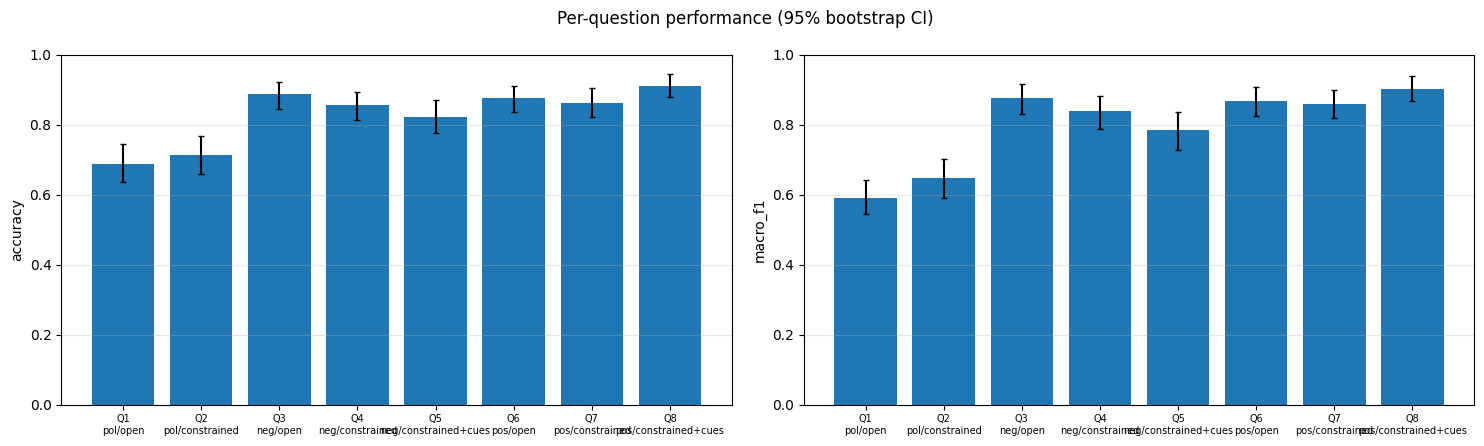

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
U.plot_metric_bars(summary, "accuracy", "acc_lo", "acc_hi", axes[0])
U.plot_metric_bars(summary, "macro_f1", "f1_lo", "f1_hi", axes[1])
fig.suptitle("Per-question performance (95% bootstrap CI)")
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "metrics_bars.png", dpi=150)
plt.show()

**What is calculated:** The accuracy and macro-F1 values from the table, as bars with 95% bootstrap CIs.

**Why:** A visual check of which differences between questions are larger than the sampling uncertainty.

**How to compare:** Non-overlapping intervals indicate a clear difference. Overlapping intervals are not conclusive; use the paired McNemar test (section 5a).

> **Result:** Q1 and Q2 are clearly below all yes/no questions. Among the yes/no questions the intervals overlap, except Q5 vs. Q8 (macro-F1 0.79 [0.73–0.84] vs. 0.90 [0.87–0.94]).

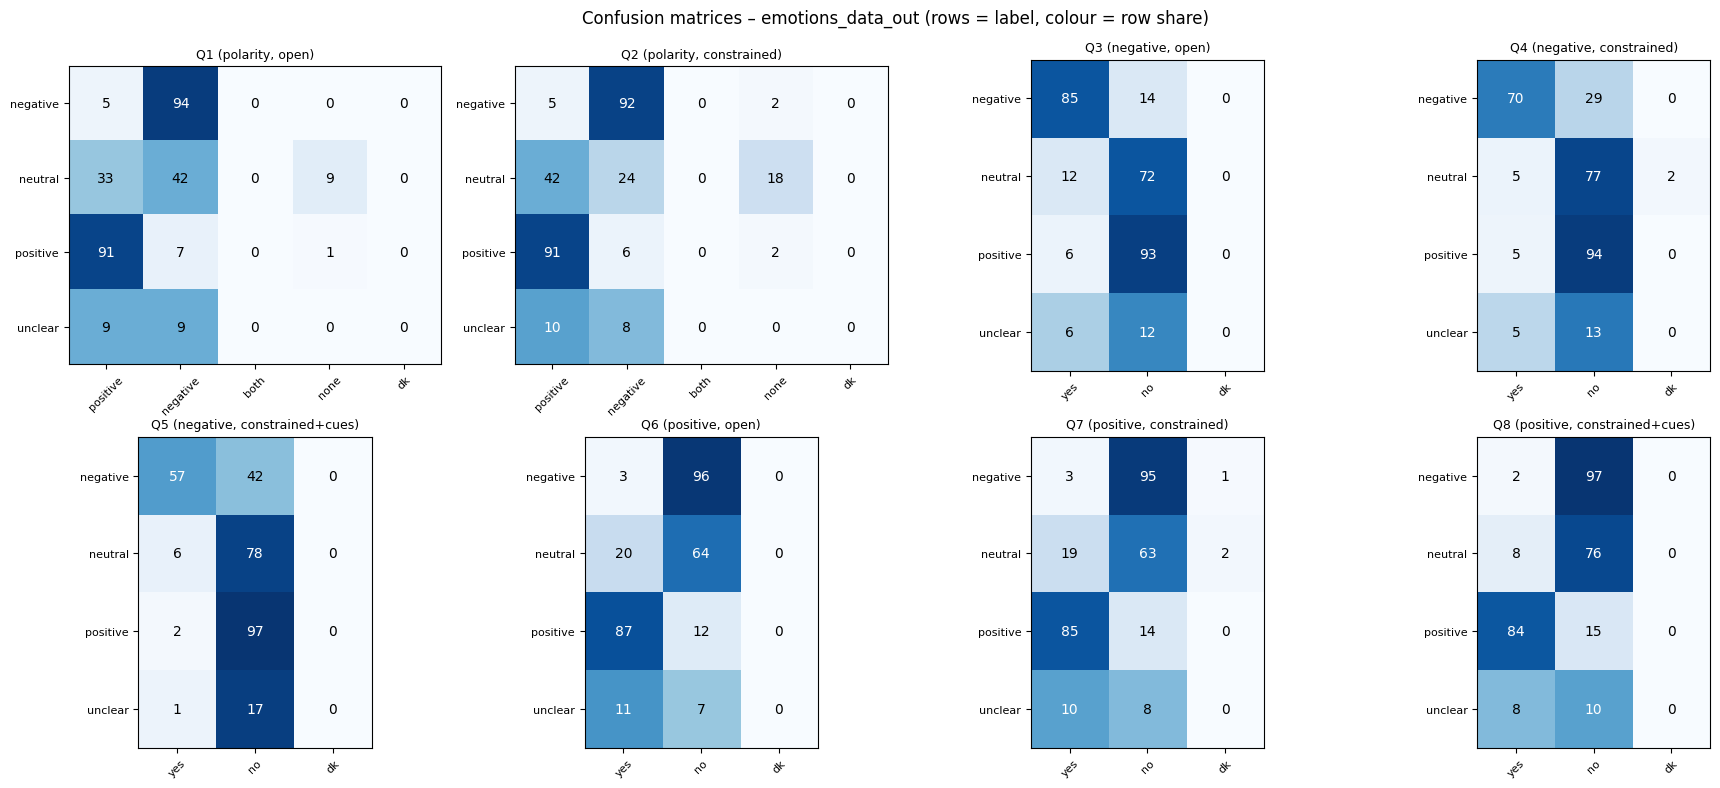

In [9]:
for m in long.model.unique():
    U.plot_confusions(long, m, OUTPUT_DIR / f"confusion_{U.safe_name(m)}.png")
plt.show()

**What is calculated:** For each question, the counts of label (rows, including *unclear*) × normalised answer (columns). The colour is the share of the row.

**Why:** It shows which kinds of errors drive the metrics, for example neutral images called negative.

**How to compare:** Correct cells (negative → negative/yes, …) should be dark and everything else light. The *unclear* row is not scored; it shows how ambiguous images are treated.

> **Result:** Almost all Q1/Q2 errors come from the neutral images. In Q1 the model calls 42 of the 84 neutral images negative and 33 positive, and only 9 "none", while positive and negative images are recognised in 91–94 of 99 cases.

## 5. Prompt-variant comparison
### 5a. Exact McNemar test on correctness (paired, same images; Holm-corrected)

In [10]:
mcn = U.mcnemar_prompts(long)
mcn.to_csv(OUTPUT_DIR / "mcnemar_prompts.csv", index=False)
mcn.round(4)

,model,pair,n,acc_first,acc_second,only_first_correct,only_second_correct,p_value,p_holm
0,emotions_data_out,Q1 vs Q2,282,0.6879,0.7128,7,14,0.1892,0.4488
1,emotions_data_out,Q3 vs Q4,282,0.8865,0.8546,15,6,0.0784,0.3134
2,emotions_data_out,Q3 vs Q5,282,0.8865,0.8227,30,12,0.0079,0.0475
3,emotions_data_out,Q4 vs Q5,282,0.8546,0.8227,20,11,0.1496,0.4488
4,emotions_data_out,Q6 vs Q7,282,0.8759,0.8617,9,5,0.4240,0.4488
5,emotions_data_out,Q6 vs Q8,282,0.8759,0.9113,6,16,0.0525,0.2624
6,emotions_data_out,Q7 vs Q8,282,0.8617,0.9113,5,19,0.0066,0.0463


**What is calculated:** For each pair of prompt variants on the same images: how many images only the first variant gets right (`only_first_correct`) and how many only the second (`only_second_correct`). An exact binomial (McNemar) test checks these two counts against each other, with Holm correction for the 7 tests.

**Why:** Both variants are answered on the same images, so a paired test is more appropriate and more powerful than comparing two independent CIs.

**How to compare:** The accuracy difference is (only_second − only_first)/n. `p_holm` < 0.05 means the wording has a significant effect.

> **Result:** Only two differences are significant. Adding cues hurts the negative question (Q3 0.89 → Q5 0.82, p_holm = 0.048) and helps the positive one (Q7 0.86 → Q8 0.91, p_holm = 0.046). Open vs. constrained wording (Q1/Q2, Q3/Q4, Q6/Q7) makes no significant difference.

### 5b. Consistency between questions
Each yes/no pair gives a polarity: (negative?, positive?) = (yes, no) → negative, (no, yes) → positive, (no, no) → none, (yes, yes) → both; anything containing dk/unparsed → dk.

In [11]:
data = U.add_derived(data)
dsum = U.question_metrics(U.derived_long(data), n_boot=N_BOOT, seed=SEED)
cols = ["model", "qid", "n_scored", "dk_rate", "accuracy", "acc_answered", "acc_lo", "acc_hi", "macro_f1", "kappa"]
pd.concat([summary[summary.target == "polarity"][cols], dsum[cols]]).round(3)

,model,qid,n_scored,dk_rate,accuracy,acc_answered,acc_lo,acc_hi,macro_f1,kappa
0,emotions_data_out,Q1,282,0.000,0.688,0.688,0.635,0.745,0.589,0.521
1,emotions_data_out,Q2,282,0.000,0.713,0.713,0.660,0.766,0.647,0.560
0,emotions_data_out,"D(Q3,Q6)",282,0.000,0.787,0.787,0.737,0.833,0.781,0.680
1,emotions_data_out,"D(Q4,Q7)",282,0.018,0.741,0.755,0.688,0.791,0.746,0.616
2,emotions_data_out,"D(Q5,Q8)",282,0.000,0.741,0.741,0.691,0.791,0.743,0.616


**What is calculated:** A polarity derived from each pair of yes/no questions (negative?, positive?), scored against the labels in the same way as Q1/Q2.

**Why:** It tests whether two separate yes/no questions give a better polarity judgement than asking for the polarity directly.

**How to compare:** Compare the D(…) rows with the Q1/Q2 rows: they use the same images and the same ground truth.

> **Result:** Two yes/no questions beat the direct question: D(Q3,Q6) reaches accuracy 0.79 (κ 0.68) against 0.69–0.71 (κ 0.52–0.56) for Q1/Q2. The main reason is that the (no, no) combination maps 52 of the 84 neutral images to "none", compared with 9 for Q1.

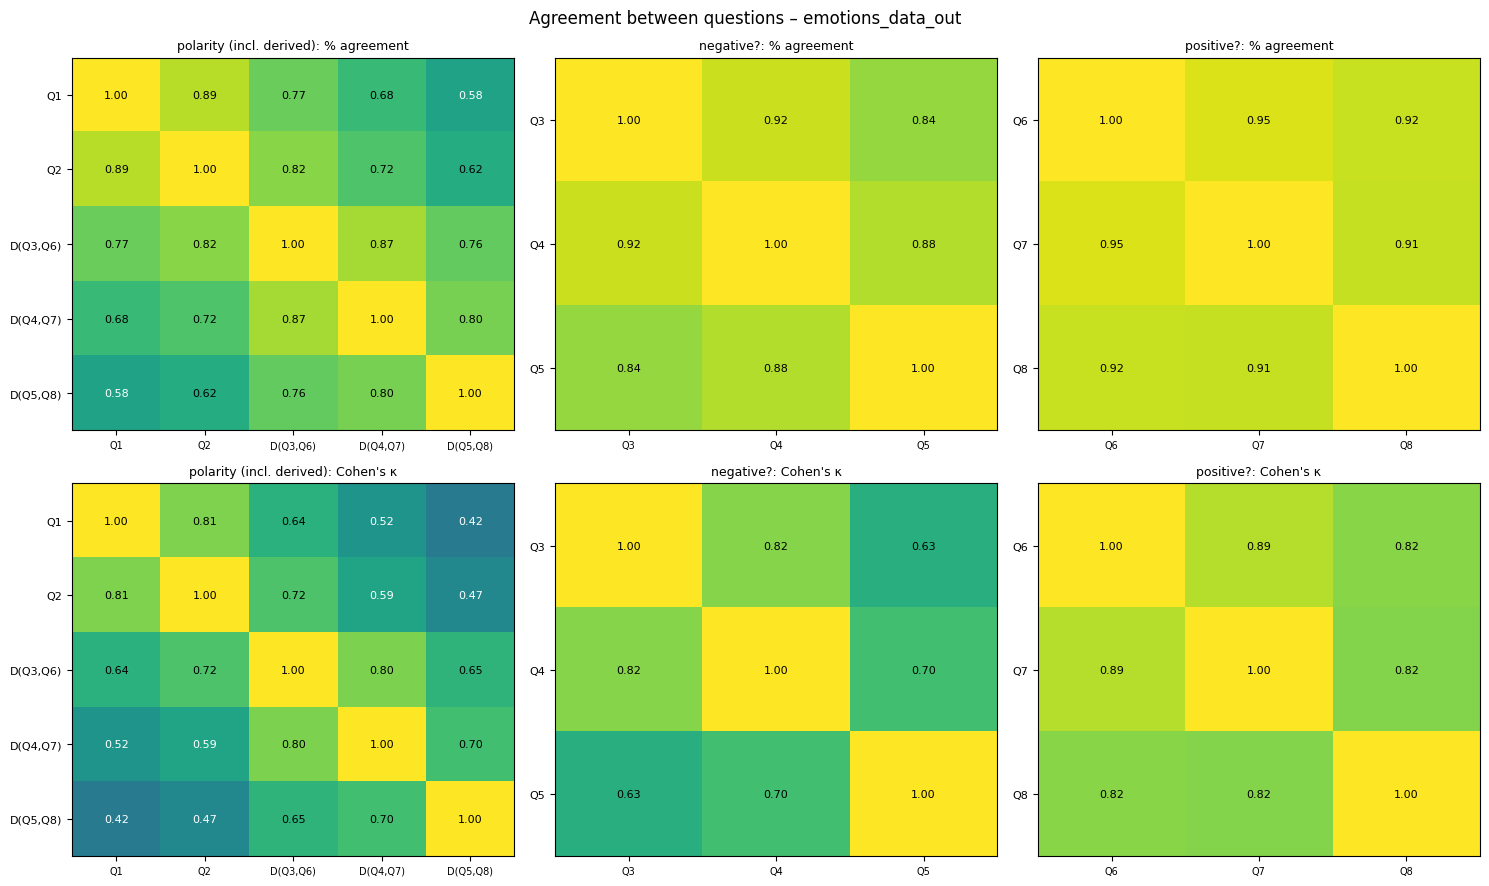

In [12]:
for m in data.model.unique():
    U.plot_agreement(data, m, OUTPUT_DIR / f"agreement_{U.safe_name(m)}.png")
plt.show()

**What is calculated:** Pairwise % agreement and Cohen's κ between the answers to different questions (answer vs. answer, not vs. the labels).

**Why:** It measures how stable the model's judgement is when the same question is rephrased.

**How to compare:** κ close to 1 means the answers barely depend on the wording; low κ means the wording changes the answer. κ guide: < 0.4 fair, 0.4–0.6 moderate, 0.6–0.8 substantial, > 0.8 almost perfect agreement.

> **Result:** Rephrasing the positive question changes little (κ 0.82–0.89 within Q6–Q8). The negative question is more sensitive (Q3 vs. Q5 κ 0.63), and the direct polarity agrees only moderately with the one derived from the cue prompts (Q1 vs. D(Q5,Q8) κ 0.42).

In [13]:
contra = U.contradictions(data)
contra.to_csv(OUTPUT_DIR / "contradictions.csv", index=False)
contra

,model,polarity_q,neg_q,pos_q,pol=positive & neg=yes,pol=negative & pos=yes,pol=none & (neg|pos)=yes,pol=positive & pos=no,pol=negative & neg=no
0,emotions_data_out,Q1,Q3,Q6,2,2,1,20,45
1,emotions_data_out,Q1,Q4,Q7,2,3,1,24,67
2,emotions_data_out,Q1,Q5,Q8,2,1,0,37,88
3,emotions_data_out,Q2,Q3,Q6,1,2,0,29,22
4,emotions_data_out,Q2,Q4,Q7,1,2,0,32,44
5,emotions_data_out,Q2,Q5,Q8,1,1,0,47,65


**What is calculated:** Counts of answer combinations that are logically inconsistent between a polarity question (Q1/Q2) and a yes/no pair.

**Why:** It checks whether the model is internally consistent across questions about the same image.

**How to compare:** The first three columns are hard contradictions (e.g. "positive" but "yes" to negative content). The last two are softer (e.g. "negative" but "no" to negative content) and indicate different thresholds. Low counts mean the model is consistent.

> **Result:** Hard contradictions are rare (≤ 3 per combination). However, the model often says "negative" in Q1 and then "no" to the negative yes/no question (45–88 times), so the yes/no questions are much more conservative than the polarity question.

## 6. Breakdown by subfolder
`neutral_vis_*_text` tests whether emotion that is only in the text of the image is picked up. The neutral images in `folder1/2` test false positives.

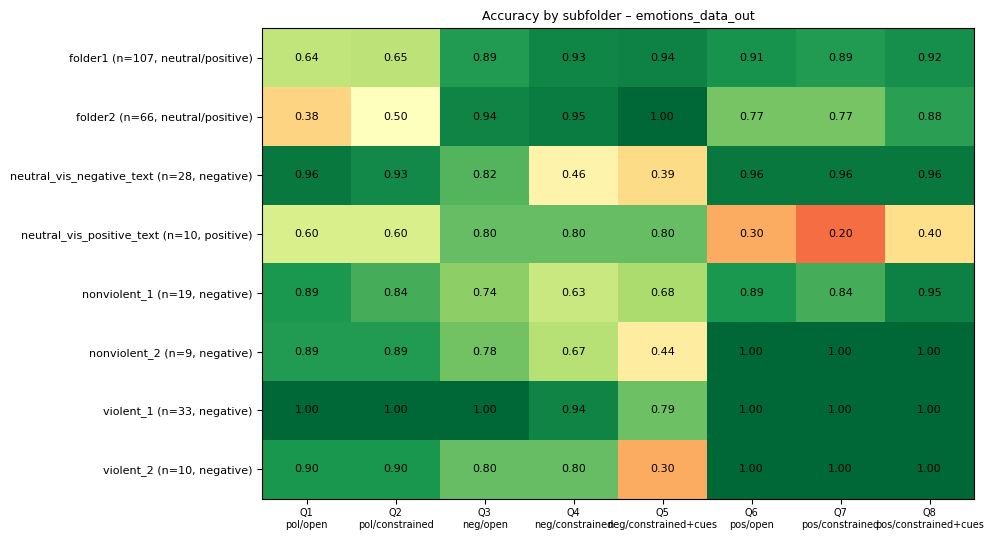

In [14]:
for m in long.model.unique():
    acc = U.subfolder_accuracy(long, m)
    acc.round(3).to_csv(OUTPUT_DIR / f"subfolder_accuracy_{U.safe_name(m)}.csv")
    fig, ax = plt.subplots(figsize=(10, 0.5 * len(acc) + 1.5))
    U.plot_heatmap(acc, f"Accuracy by subfolder – {m}", ax, xlabels=[U.qlabel(q) for q in acc.columns])
    fig.tight_layout(); fig.savefig(OUTPUT_DIR / f"subfolder_accuracy_{U.safe_name(m)}.png", dpi=150)
plt.show()

**What is calculated:** Accuracy for each subfolder (stimulus type) and question.

**Why:** The subfolders encode how the emotion is conveyed (violent / non-violent scenes, emotion only in the text, neutral images), so this shows where the model fails.

**How to compare:** Compare rows within a column. Small subfolders (n = 9–10) are noisy: one image changes the value by 0.10–0.11.

> **Result:** Emotion carried only by the text is the main weakness: for `neutral_vis_negative_text` accuracy drops from 0.82 (Q3) to 0.46 (Q4) and 0.39 (Q5), and for `neutral_vis_positive_text` the positive questions reach only 0.20–0.40. Q5 also misses many violent images (`violent_2`: 0.30).

In [15]:
# Split by label within subfolder (folder1/2 mix positive and neutral)
long[long.scored].pivot_table(index=["model", "subfolder", "emotion"], columns="qid",
                              values="correct", aggfunc="mean").round(2)

qid                                                     Q1    Q2    Q3    Q4    Q5    Q6    Q7    Q8
model             subfolder                 emotion                                                 
emotions_data_out folder1                   neutral   0.08  0.10  0.72  0.82  0.85  0.80  0.75  0.85
                                            positive  0.99  0.99  0.99  1.00  1.00  0.97  0.97  0.96
                  folder2                   neutral   0.14  0.32  0.98  1.00  1.00  0.73  0.75  0.95
                                            positive  0.86  0.86  0.86  0.86  1.00  0.86  0.82  0.73
                  neutral_vis_negative_text negative  0.96  0.93  0.82  0.46  0.39  0.96  0.96  0.96
                  neutral_vis_positive_text positive  0.60  0.60  0.80  0.80  0.80  0.30  0.20  0.40
                  nonviolent_1              negative  0.89  0.84  0.74  0.63  0.68  0.89  0.84  0.95
                  nonviolent_2              negative  0.89  0.89  0.78  0.67  0.44  1.00  1.00  1.00
                  violent_1                 negative  1.00  1.00  1.00  0.94  0.79  1.00  1.00  1.00
                  violent_2                 negative  0.90  0.90  0.80  0.80  0.30  1.00  1.00  1.00

**What is calculated:** The same accuracy, split additionally by label within each subfolder.

**Why:** `folder1` and `folder2` mix positive and neutral images, which have very different error rates.

**How to compare:** Compare the neutral and positive rows of the same folder.

> **Result:** The poor Q1/Q2 scores in `folder1`/`folder2` come entirely from the neutral images (accuracy 0.08–0.32). The positive images in the same folders are recognised in 0.86–0.99 of cases.

## 7. Images labelled *unclear* (not scored)

In [16]:
unc = data[data.emotion == "unclear"]
print(f"{unc.filename.nunique()} unclear images")
pd.concat({q: unc.groupby("model")[q + "_norm"].value_counts().unstack(fill_value=0) for q in U.POL_COLS + U.QIDS[2:]},
          names=["qid"]).fillna(0).astype(int)

18 unclear images


,,negative,positive,none,no,yes
qid,model,,,,,
Q1,emotions_data_out,9,9,0,0,0
Q2,emotions_data_out,8,10,0,0,0
"D(Q3,Q6)",emotions_data_out,6,11,1,0,0
"D(Q4,Q7)",emotions_data_out,5,10,3,0,0
"D(Q5,Q8)",emotions_data_out,1,8,9,0,0
Q3,emotions_data_out,0,0,0,12,6
Q4,emotions_data_out,0,0,0,13,5
Q5,emotions_data_out,0,0,0,17,1
Q6,emotions_data_out,0,0,0,7,11


**What is calculated:** The distribution of the model's answers for the 18 images labelled *unclear* (not scored).

**Why:** There is no ground truth for these images, but they show whether the model signals uncertainty on ambiguous images.

**How to compare:** Many "none"/"dk" answers would mean the model recognises the ambiguity; a split between positive and negative means it commits anyway.

> **Result:** The model always commits on unclear images: Q1 splits them 9 negative / 9 positive and Q2 8 / 10, with no "none" or DK.

## 8. Error inspection

In [17]:
err = (long[long.scored].groupby(["model", "filename", "emotion", "subfolder"])["correct"]
       .agg(n_wrong=lambda x: int((1 - x).sum()), n_scored="count").reset_index()
       .sort_values("n_wrong", ascending=False))
err.to_csv(OUTPUT_DIR / "per_image_errors.csv", index=False)
err.head(20)

,model,filename,emotion,subfolder,n_wrong,n_scored
222,emotions_data_out,790356_01.jpg,positive,neutral_vis_positive_text,8,8
151,emotions_data_out,775034_01.jpg,positive,neutral_vis_positive_text,8,8
124,emotions_data_out,512598.jpeg,positive,folder2,7,8
123,emotions_data_out,512463.jpeg,positive,folder2,7,8
125,emotions_data_out,514372.jpeg,positive,folder2,7,8
274,emotions_data_out,815468_04.jpg,negative,nonviolent_1,7,8
173,emotions_data_out,775145.jpg,positive,folder1,6,8
193,emotions_data_out,775312.jpg,neutral,folder1,5,8
154,emotions_data_out,775062.jpg,neutral,folder1,5,8
169,emotions_data_out,775125.jpg,neutral,folder1,5,8


**What is calculated:** For each image, the number of questions (out of 8) answered wrongly.

**Why:** It finds systematically hard images, which are either model weaknesses or possibly questionable labels.

**How to compare:** Images wrong in (almost) all questions are worth looking at, both the image and its label.

> **Result:** Two `neutral_vis_positive_text` images (790356_01.jpg, 775034_01.jpg) are wrong in all 8 questions, and three positive `folder2` images in 7 of 8. These are the first candidates for a label check.

In [18]:
# Raw answers behind the errors of one question
q = "Q5"
long[(long.qid == q) & long.scored & (long.correct == 0)][["filename", "emotion", "subfolder", "pred", "raw"]].head(30)

,filename,emotion,subfolder,pred,raw
1207,1199_03.jpg,negative,violent_1,no,no
1211,1211_05.jpg,negative,neutral_vis_negative_text,no,no
1218,1327_02.jpg,negative,violent_1,no,no
1225,1585.jpg,negative,violent_1,no,no
1227,1648.jpg,negative,violent_1,no,No
1231,1695_06.jpg,negative,violent_1,no,no
1237,1741_04.jpg,negative,violent_1,no,no
1238,1773.jpg,negative,nonviolent_1,no,no
1240,1840.jpg,negative,violent_1,no,no
1247,775034_01.jpg,positive,neutral_vis_positive_text,yes,yes


**What is calculated:** The raw answers behind the errors of one question (here Q5; change `q` to inspect others).

**Why:** It confirms the type of error behind a low score directly from the model output.

**How to compare:** Check whether the errors are misses ("no" for emotional images) or false alarms ("yes" for neutral images).

> **Result:** Most Q5 errors are plain "no" answers to negative images (42 of the 50 errors), so the cue prompt mainly causes misses, not false alarms.